# Le biais inductif spatial : quand un GNN vaut-il mieux qu'un MLP qui voit tous ses voisins ?

Sur un graphe fixe de douze nœuds, un réseau de neurones sur graphe est un cas particulier
contraint d'un perceptron qui recevrait en entrée les variables de tous les nœuds. Trois
contraintes l'en distinguent. La première restreint les échanges aux arêtes de $G$, la
deuxième impose que l'agrégation des voisins soit équivariante par permutation, la troisième
force un jeu de poids unique pour tous les nœuds. Leur réunion forme ce que Battaglia et al.
(2018) nomment le biais inductif relationnel.

Un biais n'aide qu'à deux conditions conjointes. Il doit d'abord encoder une régularité vraie
du problème. Il faut ensuite que le modèle libre ne puisse pas apprendre cette régularité à
partir des données dont il dispose. La seconde condition est celle que les comparaisons usuelles
laissent dans l'ombre, alors qu'elle décide de tout : sur douze nœuds observés pendant trois ans
au pas demi-horaire, le modèle libre dispose d'un millier de journées pour estimer une structure
que le biais lui offrirait gratuitement, et rien n'interdit qu'il y parvienne seul. Le biais cesse
alors d'être un gain et devient une contrainte, au mieux neutre.

Ce carnet sépare deux questions que la seule lecture d'un tableau de RMSE confond. La première est
mécanique et se mesure sans référence à la performance : quelle fraction de la mise à jour d'une
représentation provient effectivement des voisins ? La seconde est celle du rendement : cette
lecture des voisins se paie-t-elle en précision, une fois confrontée aux modèles libres ? On les
croise sur quatre matrices d'adjacence et quatre familles de convolution, avant de faire varier la
taille de l'échantillon d'apprentissage, axe sur lequel le biais est théoriquement censé mordre.

**Références du cadre.** Battaglia et al., *Relational inductive biases, deep learning, and graph
networks*, arXiv:1806.01261 (2018), pour le vocabulaire du biais relationnel et la thèse de
l'efficacité échantillonnale. Bronstein, Bruna, Cohen et Veličković, *Geometric Deep Learning*,
arXiv:2104.13478 (2021), pour la taxonomie convolutionnel / attentionnel / message-passing reprise
plus bas. Shuman et al., *The Emerging Field of Signal Processing on Graphs*, IEEE Signal Processing
Magazine 30(3), 2013, et Li, Yu, Shahabi, Liu, *Diffusion Convolutional Recurrent Neural Network*,
ICLR 2018, pour la pondération gaussienne des distances.

## Le plan d'expérience

Les modèles se rangent selon deux propriétés indépendantes : voient-ils les autres nœuds, et
partagent-ils leurs poids entre nœuds ? Le croisement isole ce que chaque contrainte coûte ou
rapporte.

| modèle | voit les voisins | poids partagés | agrégation contrainte |
|---|---|---|---|
| `mlp_per_node` | non | non | — |
| `mlp_shared` | non | oui | — |
| `mlp_all_per_node` | oui, tous, sans contrainte | non | non |
| `myGNN(eye)` | non | oui | — |
| `myGNN(G, conv)` | oui, via $G$ | oui | oui |

`mlp_all_per_node` est le modèle nommé dans la question de départ, celui qui voit les variables de
tous les autres nœuds sans qu'aucun graphe ne lui dise lesquels regarder. Il sert de témoin sans
biais. `myGNN(eye)` est un MLP à poids partagés déguisé en GNN, ce qui en fait le témoin exact du
graphe : la seule différence avec `myGNN(G)` tient aux arêtes. La comparaison de `mlp_per_node` à
`mlp_shared` isole quant à elle le coût du partage de poids, indépendamment de toute question de
graphe.

Deux confusions ont déjà faussé ce genre de comparaison et sont neutralisées ici. Le nombre de
paramètres est reporté partout, et la largeur des couches cachées est choisie sur validation pour
chaque famille, de sorte qu'aucun modèle ne perde pour cause de capacité mal réglée. Le protocole
d'échantillonnage est identique pour tous, les fenêtres étant alignées sur la journée.

In [ ]:
import os, sys, gc, json, time, copy, itertools, traceback
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

HERE = os.path.dirname(os.path.abspath("__file__")) or os.getcwd()
sys.path.insert(0, HERE)

from graphtoolbox.data.dataset import DataClass, GraphDataset
from graphtoolbox.models import myGNN
from graphtoolbox.training import Trainer, set_device
import torch_geometric.nn.conv as pyg_conv

set_device("cpu")   # 12-node graphs: MPS is ~5x slower than CPU here
GRAPHS = os.path.join(HERE, "graph_representations_rfrance")
OUT    = os.path.join(HERE, os.environ.get("IB_OUT", "results_inductive_bias"))
os.makedirs(OUT, exist_ok=True)

OUT_CHANNELS = 48
SEEDS        = [int(s) for s in os.environ.get("IB_SEEDS", "42,0,1").split(",")]
EPOCHS       = int(os.environ.get("IB_EPOCHS", 300))
PATIENCE     = int(os.environ.get("IB_PATIENCE", 75))
HIDDEN_GNN   = 64
NUM_LAYERS   = 2

# expe.ipynb cell 4, rfrance branch
data_kwargs = {
    "node_var": "Region",
    "dummies": ["Instant", "JourSemaine", "DayType", "offset"],
    "day_inf_train": "2015-01-01", "day_sup_train": "2018-01-01",
    "day_inf_val": "2018-01-01", "day_sup_val": "2018-12-31",
    "day_inf_test": "2019-01-01", "day_sup_test": "2019-12-31",
}
dataset_kwargs = {
    "batch_size": 32, "adj_matrix": "space",
    "features_base": ["temp", "nebu", "wind", "tempMax", "tempMin", "Posan", "Instant",
                      "JourSemaine", "JourFerie", "offset", "DayType", "Weekend",
                      "temp_liss_fort", "temp_liss_faible"] + [f"load_l{t}" for t in range(1, 49)],
    "target_base": "load",
}

# --- second feature arm: the 48 load lags swapped for the 48 target-slot temperatures ---
# computed_features receives the full frame sorted by [node_var, date], so a groupby shift(-k)
# lands the temperature of slot k of the day on the midnight row that GraphDataset reads.
def _temp_at(k):
    return lambda df: df.groupby("Region")["temp"].shift(-k)

BASE_30 = ["temp", "nebu", "wind", "tempMax", "tempMin", "Posan", "JourSemaine", "JourFerie",
           "offset", "DayType", "Weekend", "temp_liss_fort", "temp_liss_faible"]

data_kwargs_nolag = dict(data_kwargs)
data_kwargs_nolag["dummies"] = ["JourSemaine", "DayType", "offset"]   # Instant dummies are dead, see below
data_kwargs_nolag["computed_features"] = {f"temp_h{k}": _temp_at(k) for k in range(OUT_CHANNELS)}

dataset_kwargs_nolag = dict(dataset_kwargs)
dataset_kwargs_nolag["features_base"] = BASE_30 + [f"temp_h{k}" for k in range(OUT_CHANNELS)]

# --- third arm: both windows at once, past lags AND target-slot temperatures ---
data_kwargs_both = dict(data_kwargs_nolag)
dataset_kwargs_both = dict(dataset_kwargs)
dataset_kwargs_both["features_base"] = (BASE_30 + [f"temp_h{k}" for k in range(OUT_CHANNELS)]
                                        + [f"load_l{t}" for t in range(1, OUT_CHANNELS + 1)])

ARMS = {"lags":  (data_kwargs,       dataset_kwargs),
        "nolag": (data_kwargs_nolag, dataset_kwargs_nolag),
        "both":  (data_kwargs_both,  dataset_kwargs_both)}

# Every cached result carries the configuration that produced it. Without this a file written
# at one epoch budget is silently reused at another, and a single table ends up comparing models
# trained for different lengths -- which is exactly how a 150-epoch baseline came to be scored
# against a 300-epoch GNN here.
CACHE_STAMP = {"epochs": EPOCHS, "patience": PATIENCE, "seeds": SEEDS,
               "hidden_gnn": HIDDEN_GNN, "layers": NUM_LAYERS}

def _load_cache(p, name):
    if not os.path.exists(p):
        return {}
    blob = json.load(open(p))
    if "_config" not in blob:
        raise RuntimeError(f"{p} : fichier sans provenance, anterieur au marquage. Supprime-le.")
    if blob["_config"] != CACHE_STAMP:
        raise RuntimeError(
            f"{name} : le cache a ete calcule avec {blob['_config']},\n"
            f"la configuration actuelle est {CACHE_STAMP}.\n"
            f"Melanger deux budgets dans un meme tableau fausse la comparaison.\n"
            f"Supprime {p}, ou retablis la configuration precedente.")
    return blob["results"]

def _save_cache(p, res):
    json.dump({"_config": CACHE_STAMP, "results": res}, open(p, "w"), indent=1)

def cache(name, fn):
    """Run fn once, keep the result on disk. Delete the file in results_inductive_bias to redo."""
    p = os.path.join(OUT, name + ".json")
    r = _load_cache(p, name)
    if r:
        return r
    r = fn()
    _save_cache(p, r)
    return r

def cache_each(name, keys, fn, show=lambda v: ""):
    """Compute fn(key) for every key, saving after each one.

    Whole-phase caching would throw away an hour of training on any interruption, so the
    results file is rewritten entry by entry: rerunning the cell resumes where it stopped.
    A key that raises is reported and skipped rather than killing the sweep.
    """
    p = os.path.join(OUT, name + ".json")
    res = _load_cache(p, name)
    todo = [k for k in keys if k not in res]
    print(f"{name}: {len(res)} en cache, {len(todo)} a calculer", flush=True)
    failed = 0
    for k in todo:
        t0 = time.time()
        try:
            res[k] = fn(k)
            _save_cache(p, res)
            print(f"  [{k:38}] {show(res[k]):40} ({time.time()-t0:.0f}s)", flush=True)
        except Exception as e:
            failed += 1
            if failed == 1:          # the first failure carries the diagnosis; show it in full
                traceback.print_exc()
            print(f"  [{k:38}] ECHEC: {type(e).__name__}: {e}", flush=True)
    if not res:
        # Returning {} here would surface three cells later as an unrelated pandas error on an
        # empty frame, so fail where the cause is still visible.
        raise RuntimeError(f"{name}: aucune configuration n'a abouti ({failed} echecs). "
                           f"La trace ci-dessus donne la cause.")
    return res

## Les données et les quatre graphes

Les douze régions métropolitaines sont observées au pas demi-horaire, découpées en journées de
48 pas. L'apprentissage couvre 2015 à 2017, la validation 2018, le test 2019, ce qui donne
1090 journées d'apprentissage pour 362 de test. Chaque nœud porte 125 variables, dont les
48 retards de consommation de la veille et la météo locale.

Trois des quatre matrices d'adjacence sont livrées avec le dépôt. `eye` ne comporte que les boucles
sur soi et sert de témoin sans graphe. `space` est une adjacence géographique amincie, qui ne
retient que quatorze paires limitrophes sur les soixante-six possibles, et laisse par exemple
Nouvelle-Aquitaine séparée de Centre-Val-de-Loire. `dtw` est presque complet, avec 130 arêtes
orientées sur 132, et pondère les paires par la similarité des séries au sens de la déformation
temporelle dynamique.

La quatrième est construite ici. Le filtre gaussien sur graphe complet pose
$W_{ij} = \exp(-d_{ij}^2/\sigma^2)$, où $d_{ij}$ est la distance orthodromique et $\sigma$ l'écart
type des distances hors diagonale, suivant la construction usuelle en traitement du signal sur
graphe (Shuman et al., 2013) telle que la reprend DCRNN pour le trafic (Li et al., 2018). Les
distances sont prises entre préfectures de région et non entre centroïdes géométriques. Le choix
mérite d'être assumé : la préfecture approche le barycentre de la charge bien mieux que le centroïde
de la surface, puisque la consommation se concentre dans l'aire métropolitaine, et l'écart est
justement le plus marqué là où le centroïde tromperait le plus, Strasbourg et Marseille se tenant
aux bords de leurs régions respectives.

Ces quatre graphes balaient un spectre allant de l'absence d'arête à la connexion complète, et
opposent deux critères, la contiguïté et la ressemblance des séries.

In [ ]:
PREFECTURES = {   # (lat, lon) des préfectures de région, ordre alphabétique des noms de nœuds
    "Auvergne_Rhone_Alpes": (45.76, 4.83),        # Lyon
    "Bourgogne_Franche_Comte": (47.32, 5.04),     # Dijon
    "Bretagne": (48.11, -1.68),                   # Rennes
    "Centre_Val_de_Loire": (47.90, 1.90),         # Orleans
    "Grand_Est": (48.58, 7.75),                   # Strasbourg
    "Hauts_de_France": (50.63, 3.06),             # Lille
    "Ile_de_France": (48.86, 2.35),               # Paris
    "Normandie": (49.44, 1.10),                   # Rouen
    "Nouvelle_Aquitaine": (44.84, -0.58),         # Bordeaux
    "Occitanie": (43.60, 1.44),                   # Toulouse
    "Pays_de_la_Loire": (47.22, -1.55),           # Nantes
    "Provence_Alpes_Cote_d_Azur": (43.30, 5.37),  # Marseille
}

def haversine(a, b):
    R = 6371.0
    la1, lo1, la2, lo2 = map(np.radians, [a[0], a[1], b[0], b[1]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(h))

def build_gaussian(nodes, name="gaussian"):
    """W_ij = exp(-d_ij^2 / sigma^2) on the complete graph, sigma = sd of off-diagonal distances."""
    D = np.array([[haversine(PREFECTURES[a], PREFECTURES[b]) for b in nodes] for a in nodes])
    off = ~np.eye(len(nodes), dtype=bool)
    sigma = D[off].std()
    W = np.exp(-(D ** 2) / (sigma ** 2))
    np.fill_diagonal(W, 1.0)
    d = os.path.join(GRAPHS, name); os.makedirs(d, exist_ok=True)
    np.savetxt(os.path.join(d, "W.txt"), W)
    return W, D, sigma

_DATA = {}
def get_data(arm="lags"):
    if arm not in _DATA:
        _DATA[arm] = DataClass(path_train=os.path.join(HERE, "data/rfrance/train2.csv"),
                               path_test=os.path.join(HERE, "data/rfrance/test2.csv"),
                               data_kwargs=ARMS[arm][0], folder_config=HERE)
    return _DATA[arm]

_DS = {}
def resolve_adj(adj, arm):
    """The learned adjacency is arm-specific (learned end-to-end on that arm's features), so the
    virtual name 'learned' resolves to the frozen graph learned on the matching arm."""
    return f"learned_{arm}" if adj == "learned" else adj

def datasets(adj, arm="lags"):
    """Train/val/test GraphDataset triple on adjacency `adj`, scalers fitted on train."""
    if (adj, arm) in _DS:
        return _DS[(adj, arm)]
    real = resolve_adj(adj, arm)
    data = get_data(arm)
    dk = dict(ARMS[arm][1]); dk["adj_matrix"] = real
    common = dict(graph_folder=GRAPHS, dataset_kwargs=dk, out_channels=OUT_CHANNELS)
    tr = GraphDataset(data=data, period="train", **common)
    va = GraphDataset(data=data, period="val", scalers_feat=tr.scalers_feat,
                      scalers_target=tr.scalers_target, **common)
    te = GraphDataset(data=data, period="test", scalers_feat=tr.scalers_feat,
                      scalers_target=tr.scalers_target, **common)
    for ds in (tr, va, te):
        ds._set_adj_matrix(adj_matrix=real)
    _DS[(adj, arm)] = (tr, va, te)
    return _DS[(adj, arm)]

NODES = list(get_data().nodes)
W_gauss, D_km, SIGMA = build_gaussian(NODES)
print(f"sigma = {SIGMA:.0f} km   poids hors diagonale : "
      f"[{W_gauss[~np.eye(12,dtype=bool)].min():.3f}, {W_gauss[~np.eye(12,dtype=bool)].max():.3f}]")

# 'learned' is arm-specific: the row here reads the graph learned on the lags arm, with
# learned_nolag reported in the section-D comparison. Both must have been produced by the
# learn_graph.py step; a missing file drops the row rather than crashing the sweep.
ADJS = ["eye", "space", "gaussian", "dtw", "learned"]
ADJS = [a for a in ADJS
        if os.path.exists(os.path.join(GRAPHS, resolve_adj(a, "lags"), "W.txt"))]
rows = []
for a in ADJS:
    W = np.loadtxt(os.path.join(GRAPHS, resolve_adj(a, "lags"), "W.txt"))
    off = ~np.eye(12, dtype=bool)
    directed = not np.allclose(W, W.T)
    rows.append({"graphe": a, "dirige": directed,
                 "aretes hors diag": int((W[off] != 0).sum()), "sur": int(off.sum()),
                 "degre moyen": round(float((W[off] != 0).sum() / 12), 1),
                 "poids moyen": round(float(W[off][W[off] != 0].mean()) if (W[off] != 0).any() else 0.0, 3)})
pd.DataFrame(rows)

### À quoi ressemblent les graphes

Les matrices sont rendues côte à côte, avec la même échelle de couleur. Les trois premières sont
symétriques par construction, si bien que la carte est réfléchie le long de la diagonale. Le graphe
appris ne l'est pas. Comme il naît de la partie antisymétrique $M_1 M_2^\top - M_2 M_1^\top$ passée
dans une rectification, une arête et sa réciproque ne peuvent coexister, et la carte porte donc
d'un seul côté de la diagonale ce qu'une adjacence symétrique aurait dédoublé. La lecture par ligne
et par colonne n'est plus la même chose : la ligne $i$ dit de qui le nœud $i$ reçoit, la colonne $i$
à qui il envoie, distinction qu'aucun des trois premiers graphes ne peut exprimer.

In [ ]:
SHORT = {n: "".join(w[0] for w in n.split("_"))[:3].upper() for n in NODES}
labels = [SHORT[n] for n in NODES]

def load_W(name):
    p = os.path.join(GRAPHS, name, "W.txt")
    return np.loadtxt(p) if os.path.exists(p) else None

panels = [("space", "space (fixe, symetrique)"), ("dtw", "dtw (fixe, symetrique)"),
          ("learned_lags", "appris, bras lags (dirige)"),
          ("learned_nolag", "appris, bras nolag (dirige)")]
panels = [(k, t) for k, t in panels if load_W(k) is not None]

fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.0))
if len(panels) == 1:
    axes = [axes]
for ax, (key, title) in zip(axes, panels):
    W = load_W(key).copy()
    np.fill_diagonal(W, 0.0)          # hide self-loops: they are identical everywhere
    im = ax.imshow(W, cmap="magma", vmin=0, vmax=max(0.05, W.max()))
    ax.set_xticks(range(12)); ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticks(range(12)); ax.set_yticklabels(labels, fontsize=7)
    sym = "symetrique" if np.allclose(W, W.T) else "dirige"
    ax.set_title(f"{title}\n{int((W>0).sum())} aretes, {sym}", fontsize=9)
    ax.set_xlabel("vers (colonne)"); ax.set_ylabel("depuis (ligne)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

# Which regions the learned graphs single out as sources (out-edges) and sinks (in-edges).
for key in ("learned_lags", "learned_nolag"):
    W = load_W(key)
    if W is None:
        continue
    A = W.copy(); np.fill_diagonal(A, 0.0)
    out_deg, in_deg = (A > 0).sum(1), (A > 0).sum(0)
    src = sorted(range(12), key=lambda i: -out_deg[i])[:4]
    print(f"\n{key} : sources (le plus d'aretes sortantes)")
    for i in src:
        print(f"   {NODES[i]:26} {int(out_deg[i])} sorties / {int(in_deg[i])} entrees")

## Les quatre familles de convolution

La taxonomie de Bronstein et al. (2021) ordonne les couches sur graphe par la généralité du message
échangé. Le message convolutionnel ne dépend que d'un coefficient fixé par la structure, le message
attentionnel d'un poids scalaire calculé à partir des variables des deux extrémités, le message
au sens plein d'une fonction apprise du couple ordonné. On y adjoint la famille spectrale, définie
par un polynôme du laplacien. Les quatre opérateurs retenus instancient chacune de ces cases.

`ChebConv` est spectral au sens strict : sa sortie est un polynôme de degré $K$ du laplacien
normalisé (Defferrard, Bresson, Vandergheynst, NeurIPS 2016). `SAGEConv` est spatial et
convolutionnel, avec la particularité d'entretenir deux matrices distinctes, l'une pour le nœud,
l'autre pour la moyenne des voisins (Hamilton, Ying, Leskovec, NeurIPS 2017). `GATv2Conv` est
attentionnel, sa version dynamique levant la limitation de rang de l'attention statique de GAT
(Brody, Alon, Yahav, ICLR 2022). `ResGatedGraphConv` relève du message-passing, sa porte
$\sigma(W_i h_i + W_j h_j)$ modulant le message selon le couple, ce qui en fait le représentant
relationnel de la série (Bresson et Laurent, arXiv:1711.07553, 2017).

Le sens de « relationnel » retenu ici est celui du message conditionné par le couple ordonné, non
celui des relations typées de `RGCNConv`. Ce dernier exigerait des types d'arêtes que nos graphes ne
portent pas, et les fabriquer en découpant les poids en classes reviendrait à inventer une structure
que les données ne fournissent pas.

In [ ]:
CONVS = {
    "ChebConv":          dict(family="spectrale",     kwargs={"K": 3}),
    "SAGEConv":          dict(family="spatiale",      kwargs={}),
    "GATv2Conv":         dict(family="attentionnelle", kwargs={}),
    "ResGatedGraphConv": dict(family="relationnelle", kwargs={}),
}
pd.DataFrame([{"convolution": k, "famille": v["family"]} for k, v in CONVS.items()])

## Mesurer ce que les voisins apportent, et une erreur à ne pas commettre

`myGNN` empile des blocs `DeepGCNLayer(block="res+")` dont la mise à jour s'écrit
$x \leftarrow x + \mathrm{conv}(\mathrm{act}(\mathrm{norm}(x)))$. La part des voisins dans le terme
convolutif se mesure en rejouant la couche sans eux :

$$ \mathrm{part} \;=\; \frac{\lVert \mathrm{conv}(h, E) - \mathrm{conv}(h, E_{\text{ref}}) \rVert}{\lVert \mathrm{conv}(h, E) \rVert} $$

Tout se joue dans le choix de $E_{\text{ref}}$, et le choix naturel est faux. Prendre l'ensemble
d'arêtes vide retire les voisins, mais retire du même coup les boucles sur soi, que les quatre
matrices `W` livrées portent toutes sur leur diagonale. Pour `SAGEConv`, dont
$\mathrm{conv}(h, \varnothing) = W_1 h$ tandis que $\mathrm{conv}(h, E) = W_1 h + W_2 \,\mathrm{moy}(\mathcal{N}(i) \cup \{i\})$,
l'écart mesuré englobe alors le terme $W_2 h$, qui est purement auto-référentiel. La mesure attribue
aux voisins ce que le nœud se dit à lui-même.

L'ampleur de l'artefact se vérifie directement, et elle est massive. Sur le graphe `eye`, qui ne
possède aucun voisin par construction, la métrique naïve attribue 0,56 aux voisins de `SAGEConv` et
0,46 à ceux de `ResGatedGraphConv`, quand `GATv2Conv` et `ChebConv` tombent bien à zéro. L'asymétrie
n'est pas fortuite : `GATConv` et `GATv2Conv` retirent puis rajoutent les boucles en interne, si
bien que l'ensemble vide leur est équivalent, tandis que `SAGEConv` et `ResGatedGraphConv` portent
leur terme propre dans une matrice séparée. Un classement d'opérateurs établi sur cette métrique
classe donc leur traitement des boucles autant que leur usage des voisins.

La référence retenue est l'ensemble des seules boucles sur soi, c'est-à-dire l'`edge_index` du
graphe `eye`. Elle annule la part par construction sur `eye`, ce qui fournit un contrôle vérifiable,
et elle isole les mêmes voisins pour les quatre opérateurs.

Une lecture prudente de l'échelle s'impose. La quantité est un rapport de normes et non une
fraction bornée par un, si bien qu'elle peut dépasser l'unité lorsque les deux termes se
compensent partiellement. `ChebConv` s'en approche ou la franchit, ce qui se comprend sans mystère :
son opérateur est un polynôme du laplacien, de sorte que lui retirer les voisins ne retranche pas
une contribution parmi d'autres, cela le prive de sa définition même.

In [ ]:
def self_loop_edges(n=12):
    """E_ref: the 12 self-loops alone, i.e. the eye graph's edge_index."""
    i = torch.arange(n)
    return torch.stack([i, i])

def neighbour_share(model, test, ndays=20, naive=False):
    """Share of the convolution term contributed by genuine neighbours, per layer, averaged over days.

    naive=True reproduces the empty-edge reference, kept only to exhibit the self-loop artefact.
    """
    ref = torch.empty((2, 0), dtype=torch.long) if naive else self_loop_edges()
    out = []
    with torch.no_grad():
        for d in range(min(ndays, len(test))):
            g = test[d]
            x = model.node_encoder(g.x)
            sh = []
            for layer in model.layers:
                hin = layer.act(layer.norm(x))
                h = layer.conv(hin, g.edge_index)
                nb = h - layer.conv(hin, ref)
                sh.append(float(torch.norm(nb) / (torch.norm(h) + 1e-12)))
                x = x + h
            out.append(sh)
    return float(np.mean(out))

def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

### Le contrôle de la métrique

Le tableau ci-dessous entraîne brièvement chaque opérateur sur `eye` et compare les deux références.
Une colonne doit être nulle partout, l'autre non.

In [ ]:
def run_gnn(adj, conv, seed, epochs=EPOCHS, hidden=HIDDEN_GNN, train_subset=None, measure=True,
            arm="lags"):
    """Train myGNN and return (national RMSE, neighbour share, #params)."""
    tr, va, te = datasets(adj, arm)
    if train_subset is not None:
        tr = copy.copy(tr)
        tr.pyg_data = [datasets(adj, arm)[0].pyg_data[i] for i in train_subset]
    set_device("cpu"); torch.manual_seed(seed); np.random.seed(seed); gc.collect()
    m = myGNN(in_channels=te.num_node_features, num_layers=NUM_LAYERS, hidden_channels=hidden,
              out_channels=OUT_CHANNELS, conv_class=getattr(pyg_conv, conv),
              conv_kwargs=CONVS[conv]["kwargs"], heads=1)
    npar = sum(p.numel() for p in m.parameters())
    t = Trainer(model=m, dataset_train=tr, dataset_val=va, dataset_test=te, batch_size=16,
                model_kwargs={"lr": 1e-3, "num_epochs": epochs}, reconcile=False, lam_reg=0)
    pred, target, *_ = t.train(plot_loss=False, force_training=True, save=False, patience=PATIENCE)
    r = rmse(pred.sum(0).cpu().numpy(), target.sum(0).cpu().numpy())
    if not measure:
        return r, None, npar
    return r, neighbour_share(m, te), npar

def _control():
    rows = []
    for conv in CONVS:
        tr, va, te = datasets("eye")
        set_device("cpu"); torch.manual_seed(42)
        m = myGNN(in_channels=te.num_node_features, num_layers=NUM_LAYERS, hidden_channels=HIDDEN_GNN,
                  out_channels=OUT_CHANNELS, conv_class=getattr(pyg_conv, conv),
                  conv_kwargs=CONVS[conv]["kwargs"], heads=1)
        rows.append({"convolution": conv,
                     "part naive (aretes vides)": round(neighbour_share(m, te, ndays=5, naive=True), 4),
                     "part corrigee (boucles seules)": round(neighbour_share(m, te, ndays=5), 4)})
    return rows

ctrl = pd.DataFrame(cache("control_metric", _control))
print("Graphe eye : aucun voisin n'existe. Toute part non nulle est un artefact.")
ctrl

## Les modèles libres

Trois perceptrons servent de témoins. `mlp_per_node` entraîne douze réseaux indépendants, chacun sur
les 125 variables de sa région. `mlp_shared` entraîne un réseau unique sur les mêmes variables, les
douze régions étant versées dans un même échantillon, ce qui reproduit exactement la contrainte de
partage de poids du GNN sans lui donner d'arêtes. `mlp_all_per_node` entraîne douze réseaux
indépendants sur la concaténation des 1500 variables des douze régions, et c'est le modèle sans
aucun biais : il voit tout le monde et personne ne lui dit qui regarder.

La largeur cachée est choisie sur la validation parmi trois valeurs, pour chaque famille séparément.
Sans cela, la comparaison mesurerait un réglage plutôt qu'une architecture, faute déjà rencontrée
lorsque des modèles de 31 000 et de 228 000 paramètres avaient été opposés.

In [ ]:
def stack(ds):
    return np.stack([d.x.numpy() for d in ds]), np.stack([d.y.numpy() for d in ds])

def _fit_mlp(a, yt, b, yv, c, hidden, epochs, seed, out_dim=OUT_CHANNELS):
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Linear(a.shape[1], hidden), nn.ReLU(),
                      nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, out_dim))
    opt = torch.optim.Adam(m.parameters(), lr=1e-3); lf = nn.MSELoss()
    best, state, bad = 1e18, None, 0
    for _ in range(epochs):
        m.train(); perm = torch.randperm(len(a))
        for k in range(0, len(a), 64):
            i = perm[k:k + 64]
            opt.zero_grad(); lf(m(a[i]), yt[i]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(b), yv))
        if vl < best - 1e-6:
            best, state, bad = vl, {k: v.clone() for k, v in m.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    m.load_state_dict(state); m.eval()
    with torch.no_grad():
        return m(c).numpy(), best, sum(p.numel() for p in m.parameters())

def _z(A, ref):
    """Standardise A with ref's moments.

    A feature that is constant within ref must be zeroed, not divided by ~0. At small training
    fractions the rare calendar dummies do go constant while still varying in test, and dividing
    by std+1e-6 then maps them to ~1e6, which is what made the MLP diverge on the sample curve.
    """
    mu, sg = ref.mean(0), ref.std(0)
    dead = sg < 1e-8
    sg = np.where(dead, 1.0, sg)
    Z = (A - mu) / sg
    Z[:, dead] = 0.0
    return torch.tensor(Z, dtype=torch.float32)

def run_mlp(kind, seed, hidden, epochs=EPOCHS, train_subset=None, arm="lags"):
    """kind in {per_node, shared, all_per_node}. Returns (national RMSE, val loss, #params)."""
    tr, va, te = datasets("eye", arm)
    Xtr, Ytr = stack(tr); Xva, Yva = stack(va); Xte, Yte = stack(te)
    if train_subset is not None:
        Xtr, Ytr = Xtr[train_subset], Ytr[train_subset]
    N = Xtr.shape[1]
    pred, vls, npar = np.zeros_like(Yte), [], 0

    if kind == "shared":
        A = Xtr.reshape(-1, Xtr.shape[2]); B = Xva.reshape(-1, Xva.shape[2]); Cc = Xte.reshape(-1, Xte.shape[2])
        ya = Ytr.reshape(-1, OUT_CHANNELS); yb = Yva.reshape(-1, OUT_CHANNELS)
        ym, ys = ya.mean(), ya.std() + 1e-6
        p, vl, npar = _fit_mlp(_z(A, A), torch.tensor((ya - ym) / ys, dtype=torch.float32),
                               _z(B, A), torch.tensor((yb - ym) / ys, dtype=torch.float32),
                               _z(Cc, A), hidden, epochs, seed)
        pred = (p * ys + ym).reshape(Yte.shape); vls = [vl]
    else:
        for i in range(N):
            if kind == "per_node":
                A, B, Cc = Xtr[:, i, :], Xva[:, i, :], Xte[:, i, :]
            elif kind == "all_per_node":
                A = Xtr.reshape(len(Xtr), -1); B = Xva.reshape(len(Xva), -1); Cc = Xte.reshape(len(Xte), -1)
            else:
                raise ValueError(kind)
            ym, ys = Ytr[:, i, :].mean(), Ytr[:, i, :].std() + 1e-6
            p, vl, np_i = _fit_mlp(_z(A, A), torch.tensor((Ytr[:, i, :] - ym) / ys, dtype=torch.float32),
                                   _z(B, A), torch.tensor((Yva[:, i, :] - ym) / ys, dtype=torch.float32),
                                   _z(Cc, A), hidden, epochs, seed)
            pred[:, i, :] = p * ys + ym; vls.append(vl); npar += np_i
    return rmse(pred.sum(1).ravel(), Yte.sum(1).ravel()), float(np.mean(vls)), npar

## Expérience A et B : mécanisme et rendement

Un même entraînement livre les deux mesures, la part des voisins et le RMSE national. La grille
croise les quatre graphes et les quatre convolutions, sur trois graines. Les écarts entre opérateurs
n'ont de sens que rapportés à la dispersion entre graines, laquelle avait atteint 42 MW dans des
mesures antérieures sur un jeu voisin, soit davantage que l'écart total entre six opérateurs.

In [ ]:
def _grid_one(k):
    adj, conv, s = k.split("|")
    r, sh, npar = run_gnn(adj, conv, int(s))
    return {"rmse": r, "share": sh, "params": npar}

grid = cache_each("grid_adj_conv",
                  [f"{a}|{c}|{s}" for a, c in itertools.product(ADJS, CONVS) for s in SEEDS],
                  _grid_one,
                  show=lambda v: f"RMSE {v['rmse']:6.0f}  part {v['share']:.4f}")

recs = []
for k, v in grid.items():
    a, c, s = k.split("|")
    recs.append({"graphe": a, "convolution": c, "graine": int(s), **v})
G = pd.DataFrame(recs)

def piv(val, how):
    return (G.pivot_table(index="convolution", columns="graphe", values=val, aggfunc=how)
             .reindex(index=list(CONVS), columns=ADJS))

share, rmse_m = piv("share", "mean"), piv("rmse", "mean")
rmse_s = piv("rmse", "std").fillna(0.0)   # std is NaN when a single seed was run

print("Part des voisins dans le terme convolutif (moyenne sur graines).")
print("La colonne eye doit etre nulle : c'est le controle de la metrique.\n")
display(share.round(3))
print("\nRMSE national en MW (moyenne +/- ecart type sur graines)\n")
display(rmse_m.round(0).astype("Int64").astype(str) + " +/- " + rmse_s.round(0).astype(int).astype(str))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, M, title, fmt in ((axes[0], share, "Part des voisins", "{:.3f}"),
                          (axes[1], rmse_m, "RMSE national (MW)", "{:.0f}")):
    im = ax.imshow(M.values, cmap="viridis" if M is share else "viridis_r", aspect="auto")
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns)
    ax.set_yticks(range(len(M.index))); ax.set_yticklabels(M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M.values[i, j]), ha="center", va="center",
                    color="w", fontsize=9)
    ax.set_title(title); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

sd = G.groupby(["graphe", "convolution"])["rmse"].std().fillna(0).mean()
sp = np.nanmax(rmse_m.values) - np.nanmin(rmse_m.values)
print(f"Dispersion moyenne entre graines : {sd:.0f} MW")
print(f"Etendue totale des moyennes sur les 16 cases : {sp:.0f} MW")
print("Un classement des cases n'a de sens que si l'etendue depasse nettement la dispersion.")

### Le rendement, face aux modèles libres

Les trois perceptrons sont maintenant entraînés, leur largeur choisie sur validation. La ligne à
lire est l'écart entre le meilleur GNN et `mlp_all_per_node` : le premier voit les voisins à travers
le graphe et sous contrainte d'équivariance, le second les voit tous et sans contrainte. Si le biais
apporte quelque chose sur ce volume de données, il doit apparaître ici.

In [ ]:
MLP_HIDDEN = [int(h) for h in os.environ.get("IB_MLP_HIDDEN", "32,64,128").split(",")]

def _base_one(k):
    kind, h, s = k.split("|")
    r, vl, npar = run_mlp(kind, int(s), int(h))
    return {"rmse": r, "val": vl, "params": npar}

base = cache_each("baselines",
                  [f"{k}|{h}|{s}" for k in ("per_node", "shared", "all_per_node")
                   for h in MLP_HIDDEN for s in SEEDS],
                  _base_one,
                  show=lambda v: f"RMSE {v['rmse']:6.0f}  val {v['val']:.4f}  par {v['params']}")

B = pd.DataFrame([{"modele": k.split("|")[0], "hidden": int(k.split("|")[1]),
                   "graine": int(k.split("|")[2]), **v} for k, v in base.items()])
# width selected on validation, seeds averaged
sel = B.groupby(["modele", "hidden"])["val"].mean().reset_index()
best_h = sel.loc[sel.groupby("modele")["val"].idxmin()].set_index("modele")["hidden"].to_dict()
print("Largeur retenue sur validation :", best_h, "\n")

def _sd(x):
    v = x.std()
    return 0 if pd.isna(v) else round(v)

lines = []
for m, h in best_h.items():
    d = B[(B.modele == m) & (B.hidden == h)]
    lines.append({"modele": m, "hidden": h, "voit les voisins": m == "all_per_node",
                  "poids partages": m == "shared",
                  "RMSE": round(d.rmse.mean()), "sd": _sd(d.rmse),
                  "params": int(d.params.iloc[0])})
for conv in CONVS:
    for a in ADJS:
        d = G[(G.convolution == conv) & (G.graphe == a)]
        if len(d) == 0:
            continue
        lines.append({"modele": f"myGNN({a}, {conv})", "hidden": HIDDEN_GNN,
                      "voit les voisins": a != "eye", "poids partages": True,
                      "RMSE": round(d.rmse.mean()), "sd": _sd(d.rmse),
                      "params": int(d.params.iloc[0])})
T = pd.DataFrame(lines).sort_values("RMSE").reset_index(drop=True)
T

## Expérience C : l'axe où le biais est censé mordre

Les deux expériences précédentes se tiennent à volume de données fixé, et c'est leur limite. La
thèse de Battaglia et al. ne dit pas qu'un biais relationnel rend meilleur, elle dit qu'il rend
plus efficace en échantillons : il restreint l'espace des hypothèses, donc il paie tant que les
données ne suffisent pas à identifier la structure, et il devient inutile dès qu'elles suffisent.
Comparer les modèles sur les mille journées complètes ne teste donc pas le biais, cela teste le
biais dans le seul régime où la théorie prédit qu'il ne sert à rien.

L'expérience fait varier la fraction des journées d'apprentissage retenues, de cinq pour cent à la
totalité, à validation et test inchangés. Le sous-échantillon est tiré au hasard plutôt que pris
en fin de période, de sorte que la couverture saisonnière reste entière et que seule la taille de
l'échantillon varie. La prédiction est nette et falsifiable. Si le biais spatial est réel,
`myGNN(space)` doit dominer `mlp_all_per_node` à cinq et dix pour cent, l'écart se refermant à
mesure que les données arrivent. Si les deux courbes restent confondues jusqu'en bas, alors le
graphe n'encode aucune régularité que le modèle libre ne trouve seul, et le biais spatial n'est pas
établi sur ces douze nœuds.

In [ ]:
FRACTIONS = [float(f) for f in os.environ.get("IB_FRACTIONS", "0.05,0.10,0.25,0.50,1.00").split(",")]
N_TRAIN   = len(datasets("eye")[0])

def subset(frac, seed):
    rng = np.random.default_rng(1000 + seed)
    k = max(16, int(round(frac * N_TRAIN)))
    return sorted(rng.choice(N_TRAIN, size=k, replace=False).tolist())

CURVE_CONV = "SAGEConv"

MODELS_C = ("gnn_space", "gnn_eye", "mlp_all_per_node", "mlp_per_node")

def _curve_one(k):
    name, frac, s = k.split("|")
    s = int(s); idx = subset(float(frac), s)
    if name.startswith("gnn"):
        r, _, npar = run_gnn(name.split("_")[1], CURVE_CONV, s, train_subset=idx, measure=False)
    else:
        kind = name[4:]
        r, _, npar = run_mlp(kind, s, best_h[kind], train_subset=idx)
    return {"rmse": r, "n": len(idx), "params": npar}

curve = cache_each("sample_curve",
                   [f"{m}|{f}|{s}" for f in FRACTIONS for s in SEEDS for m in MODELS_C],
                   _curve_one,
                   show=lambda v: f"n={v['n']:4}  RMSE {v['rmse']:6.0f}")
Cv = pd.DataFrame([{"modele": k.split("|")[0], "frac": float(k.split("|")[1]),
                    "graine": int(k.split("|")[2]), **v} for k, v in curve.items()])
Cv.pivot_table(index="frac", columns="modele", values="rmse", aggfunc="mean").round(0)

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
style = {"gnn_space": ("o-", "Reseau sur graphe (space, SAGE)"),
         "gnn_eye": ("s--", "Reseau sans graphe (eye, SAGE)"),
         "mlp_all_per_node": ("^-", "MLP/noeud voyant tous les noeuds"),
         "mlp_per_node": ("v:", "MLP/noeud, variables propres")}
for m, (st, lab) in style.items():
    d = Cv[Cv.modele == m].groupby("n")["rmse"].agg(["mean", "std"])
    if len(d) == 0:
        continue
    ax.errorbar(d.index, d["mean"], yerr=d["std"], fmt=st, capsize=3, label=lab)
ax.set_xscale("log"); ax.set_xlabel("journees d'apprentissage")
ax.set_ylabel("RMSE national (MW)")
ax.set_title("Le biais spatial paie-t-il quand les donnees manquent ?")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Ecart mlp_all_per_node - gnn_space, en MW (positif = le graphe aide) :\n")
g = Cv[Cv.modele == "gnn_space"].groupby("n")["rmse"].mean()
m = Cv[Cv.modele == "mlp_all_per_node"].groupby("n")["rmse"].mean()
sd = Cv.groupby(["modele", "n"])["rmse"].std().fillna(0).mean()
print((m - g).round(0).to_string())
print(f"\nDispersion moyenne entre graines : {sd:.0f} MW. "
      f"Un ecart inferieur a cette valeur n'est pas interpretable.")

## Expérience D : ce que devient le graphe quand on retire la béquille auto-régressive

Il faut d'abord regarder ce que `GraphDataset` donne réellement à lire au modèle, car la
construction décide de tout ce qui précède. La boucle de `_prepare_graph_data` retient
`x_t = X_all[:, start]`, c'est-à-dire une seule ligne de variables, prise au premier pas de chaque
journée, tandis que la cible `y_t = Y_scaled[:, start:end]` couvre les quarante-huit pas suivants.
Chaque graphe est donc une journée, et le modèle prédit tout le profil du jour depuis l'instant
minuit.

Trois conséquences en découlent, dont deux passent inaperçues. Les variables météorologiques `temp`,
`nebu` et `wind` ne valent que leur relevé de minuit, si bien que le modèle ignore le temps qu'il
fera aux heures mêmes qu'il prédit. Les quarante-sept indicatrices `Instant_1` à `Instant_47` sont
identiquement nulles sur tous les graphes, puisque le pas retenu est toujours le premier de la
journée, et la vérification le confirme : sur les cent vingt-cinq variables annoncées, quarante-sept
sont constantes et soixante-dix-huit seulement portent de l'information. Les `load_l1` à `load_l48`
enfin, évaluées à minuit du jour $D$, valent exactement les quarante-huit pas du jour $D-1$.

Le compte est alors éloquent. Des soixante-dix-huit variables vivantes, quarante-huit sont les
retards de la cible, et ce sont les seules à renseigner le niveau de charge : tout le reste est
météo de minuit et calendrier. La persistance n'est pas une variable parmi d'autres, elle est le
prédicteur, et le graphe ne peut espérer se voir confier que le résidu qu'elle laisse. Le biais
auto-régressif écrase le biais spatial avant même que celui-ci ait eu l'occasion de se manifester.

L'expérience échange donc les quarante-huit retards contre les quarante-huit températures aux pas
que l'on prédit, les trente autres variables demeurant identiques. La parité est exacte, soixante-dix-huit
variables vivantes de part et d'autre, et un seul facteur change : le nœud sait-il ce qu'il
consommait hier, ou seulement le temps qu'il fera aujourd'hui. L'hypothèse est que le graphe, privé
de concurrent, devient enfin lisible.

Une réserve doit être posée franchement. Les températures aux pas cibles sont les températures
réalisées, ce qui revient à supposer une prévision météorologique parfaite. La convention est celle
du domaine, où la prévision à un jour s'appuie sur les sorties d'un modèle numérique, mais elle
avantage le bras sans retards et l'écart mesuré est donc à lire comme une borne favorable. Ce bras
n'est pas un concurrent du protocole du papier, c'est un instrument de diagnostic.

In [ ]:
def live_features(arm):
    tr, _, te = datasets("eye", arm)
    X = np.stack([d.x.numpy() for d in tr])
    sd = X.reshape(-1, X.shape[2]).std(0)
    f = tr.features
    live = [f[i] for i in range(len(f)) if sd[i] >= 1e-9]
    dead = [f[i] for i in range(len(f)) if sd[i] < 1e-9]
    return f, live, dead

rows = []
for arm in ARMS:
    f, live, dead = live_features(arm)
    rows.append({"bras": arm, "variables": len(f), "mortes": len(dead), "vivantes": len(live),
                 "dont retards de charge": len([x for x in live if x.startswith("load_l")]),
                 "dont temp. aux pas cibles": len([x for x in live if x.startswith("temp_h")])})
display(pd.DataFrame(rows))

_, _, dead_lags = live_features("lags")
print(f"\nBras 'lags' : {len(dead_lags)} variables constantes sur tous les graphes.")
print("Exemples :", dead_lags[:4], "...", dead_lags[-2:])

In [ ]:
def _grid_nolag_one(k):
    adj, conv, s = k.split("|")
    r, sh, npar = run_gnn(adj, conv, int(s), arm="nolag")
    return {"rmse": r, "share": sh, "params": npar}

grid_nolag = cache_each("grid_adj_conv_nolag",
                        [f"{a}|{c}|{s}" for a, c in itertools.product(ADJS, CONVS) for s in SEEDS],
                        _grid_nolag_one,
                        show=lambda v: f"RMSE {v['rmse']:6.0f}  part {v['share']:.4f}")

GN = pd.DataFrame([{"graphe": k.split("|")[0], "convolution": k.split("|")[1],
                    "graine": int(k.split("|")[2]), **v} for k, v in grid_nolag.items()])

def piv2(df, val, how):
    return (df.pivot_table(index="convolution", columns="graphe", values=val, aggfunc=how)
              .reindex(index=list(CONVS), columns=ADJS))

share_n, rmse_n = piv2(GN, "share", "mean"), piv2(GN, "rmse", "mean")
print("Bras sans retards. Part des voisins (moyenne sur graines)\n")
display(share_n.round(3))
print("\nBras sans retards. RMSE national en MW\n")
display(rmse_n.round(0).astype("Int64"))

In [ ]:
# Does removing the autoregressive crutch make the graph matter?
comp = []
for a in ADJS:
    for c in CONVS:
        dl = G[(G.graphe == a) & (G.convolution == c)]
        dn = GN[(GN.graphe == a) & (GN.convolution == c)]
        if len(dl) == 0 or len(dn) == 0:
            continue
        comp.append({"graphe": a, "convolution": c,
                     "part lags": round(dl.share.mean(), 3), "part nolag": round(dn.share.mean(), 3),
                     "RMSE lags": round(dl.rmse.mean()), "RMSE nolag": round(dn.rmse.mean())})
CP = pd.DataFrame(comp)

# The graph's own contribution, measured within each arm against that arm's eye baseline.
print("Gain du graphe par rapport a eye, DANS chaque bras (positif = le graphe aide)\n")
gain = []
for arm, df in (("lags", G), ("nolag", GN)):
    eye = df[df.graphe == "eye"].groupby("convolution")["rmse"].mean()
    for a in [x for x in ADJS if x != "eye"]:
        d = df[df.graphe == a].groupby("convolution")["rmse"].mean()
        for c in d.index:
            gain.append({"bras": arm, "graphe": a, "convolution": c,
                         "gain_MW": eye[c] - d[c],
                         "gain_pct": 100 * (eye[c] - d[c]) / eye[c]})
GA = pd.DataFrame(gain)
display(GA.pivot_table(index="convolution", columns=["bras", "graphe"], values="gain_MW").round(0))

print("\nResume par bras :")
for arm in ("lags", "nolag"):
    d = GA[GA.bras == arm]
    sdev = (G if arm == "lags" else GN).groupby(["graphe", "convolution"])["rmse"].std().fillna(0).mean()
    print(f"  {arm:6} : gain moyen du graphe {d.gain_MW.mean():+6.0f} MW "
          f"({d.gain_pct.mean():+.1f} %)   dispersion entre graines {sdev:.0f} MW")
display(CP)

## Expérience E : empiler plutôt que juxtaposer

La pratique opérationnelle n'ajuste pas un modèle unique. Elle ajuste d'abord un modèle sans
retards, afin que la réponse aux covariables s'apprenne pour elle-même, puis lui adjoint une
correction fondée sur les retards. La lignée développée autour d'EDF en donne la forme, un modèle
additif sur météo et calendrier corrigé en ligne (Ba, Sinn, Goude, Pompey, *Adaptive learning of
smoothing functions*, NeurIPS 2012 ; Nedellec, Cugliari, Goude, *GEFCom2012*, IJF 30(2), 2014).

Il faut voir pourquoi ce détour n'est pas une maladresse. Donnez à un modèle unique les retards et
les covariables, il empruntera le chemin le plus court, la persistance expliquant l'essentiel et la
réponse météorologique n'héritant que du résidu. Retirer les retards au premier étage n'appauvrit
pas le modèle, cela **force l'attribution de la variance commune** vers les covariables. Le premier
étage est un handicap délibéré.

D'où le point qui commande toute cette section. Séparer les entrées en bras parallèles ne reproduit
pas ce comportement, car sous une perte unique le gradient continue d'emprunter le bras des retards,
quelle que soit la façon dont on cloisonne l'amont. L'`AdditiveGraphModel` de la bibliothèque en
administre la preuve : c'est déjà un modèle multi-bras, et les retards y dominent tout de même. Ce
qui fait tenir le deux-étages n'est pas sa topologie, c'est que **le premier étage possède sa propre
perte contre $y$**, et qu'il est figé avant l'ajustement du second.

La forme retenue est donc une pile, et non une juxtaposition. Le premier étage prédit
$\hat y_1$ depuis les covariables, le second lit les retards et $\hat y_1$, et la sortie est
additive, $\hat y = \hat y_1 + \hat y_2$. L'additivité contraint, là où $\hat y = B([\hat y_1, \text{lags}])$
rendrait au second étage la liberté d'annuler le premier.

Deux régimes d'ajustement sont mis à l'épreuve, faute de savoir lequel vaut mieux.

Le régime **gelé** ajuste le premier étage seul, le fige, puis ajuste le second sur le résidu. Il
reproduit l'opérationnel exactement. Un piège s'y attache, qui décide de tout : les résidus calculés
sur les données ayant servi à ajuster le premier étage sont optimistes, puisque celui-ci les a
partiellement mémorisés, et le second apprend alors sur une distribution de résidus qui n'est pas
celle du test. Le remède est le cross-fitting, des résidus hors-échantillon obtenus par $K$ replis
(Wolpert, *Stacked generalization*, Neural Networks 5(2), 1992), et il est appliqué ici.

Le régime **conjoint à perte auxiliaire** optimise
$\mathcal{L} = \mathcal{L}(\hat y, y) + \lambda\,\mathcal{L}(\hat y_1, y)$. Il transforme le handicap
en une quantité réglable : $\lambda = 0$ redonne la pile sans supervision intermédiaire, c'est-à-dire
le piège décrit plus haut, où $\hat y_1$ n'est qu'une variable latente arbitraire, tandis qu'un
$\lambda$ grand approche le régime gelé sans le gel. Le balayage répond directement à la question
que la seule pratique opérationnelle laisse ouverte, celle de savoir si l'étagement achète de la
précision ou seulement de l'attribution et de la robustesse.

Reste la question qui a lancé tout ce carnet, et qui trouve ici sa forme la plus nette. Où le graphe
sert-il ? Le pari est qu'il appartient au premier étage, la réponse aux covariables étant spatiale
puisqu'un front traverse plusieurs régions, quand le résidu du second est ce que la persistance
locale n'a pas capté, donc local par nature. La comparaison de `eye` à `space`, menée séparément
pour chaque étage, tranche ce pari.

Ce pari a une conséquence sur la forme du second étage, que le régime gelé initial ignorait en y
plaçant encore un réseau sur graphe. Si le résidu est local, lui réappliquer un graphe revient à
chercher du voisinage là où l'on a justement mesuré qu'il n'y en avait plus, le graphe n'apportant
qu'une poignée de mégawatts sur le bras des retards. Le second étage doit alors être une correction
autorégressive par nœud, douze modèles indépendants sans aucune arête, apprise sur le même résidu
hors-échantillon. Le régime `frozen (etage2 = AR/noeud)` instancie ce choix, et sa comparaison au
régime `frozen (etage2 = GNN)`, tout le reste égal, isole la seule question qui reste : sur le
résidu, une correction locale vaut-elle mieux qu'un second graphe.

In [27]:
from torch_geometric.loader import DataLoader as PyGLoader

def feature_split(arm="both"):
    """Indices of the covariate window (everything that is not a lag of the target) and of the lags."""
    f = datasets("eye", arm)[0].features
    cov = [i for i, n in enumerate(f) if not n.startswith("load_l")]
    lag = [i for i, n in enumerate(f) if n.startswith("load_l")]
    return cov, lag

class StackedGNN(nn.Module):
    """Stage 1 reads the covariates, stage 2 reads the lags and stage 1's output; outputs add.

    Returns (y_hat, y1) so a caller can supervise the first stage directly. `detach_stage1`
    severs the gradient path from stage 2 back into stage 1, which is what "frozen" needs.
    """
    def __init__(self, cov_idx, lag_idx, conv, hidden, layers, out, detach_stage1=False):
        super().__init__()
        self.cov_idx, self.lag_idx = cov_idx, lag_idx
        self.detach_stage1 = detach_stage1
        mk = lambda nin: myGNN(in_channels=nin, num_layers=layers, hidden_channels=hidden,
                               out_channels=out, conv_class=getattr(pyg_conv, conv),
                               conv_kwargs=CONVS[conv]["kwargs"], heads=1)
        self.stage1 = mk(len(cov_idx))
        self.stage2 = mk(len(lag_idx) + out)
        self.hidden_channels, self.num_layers = hidden, layers

    def forward(self, x, edge_index, **kw):
        y1 = self.stage1(x[:, self.cov_idx], edge_index, **kw)
        y1_in = y1.detach() if self.detach_stage1 else y1
        y2 = self.stage2(torch.cat([x[:, self.lag_idx], y1_in], dim=-1), edge_index, **kw)
        return y1 + y2, y1

class FlatGNN(nn.Module):
    """Reference: one encoder over the concatenation, i.e. no staging at all."""
    def __init__(self, nin, conv, hidden, layers, out):
        super().__init__()
        self.net = myGNN(in_channels=nin, num_layers=layers, hidden_channels=hidden,
                         out_channels=out, conv_class=getattr(pyg_conv, conv),
                         conv_kwargs=CONVS[conv]["kwargs"], heads=1)
        self.hidden_channels, self.num_layers = hidden, layers
    def forward(self, x, edge_index, **kw):
        y = self.net(x, edge_index, **kw)
        return y, None

In [28]:
def _epoch(model, loader, opt, num_nodes, aux_lambda=0.0, train=True, target_override=None):
    """One pass. Mirrors Trainer._run_epoch: masked MSE on the scaled target."""
    model.train() if train else model.eval()
    tot, cnt = 0.0, 0
    for i, batch in enumerate(loader):
        for a in ("x", "y_scaled", "y", "edge_weight", "mask_y"):
            if getattr(batch, a, None) is not None:
                setattr(batch, a, getattr(batch, a).to(torch.float32))
        if torch.isnan(batch.x).any() or torch.isnan(batch.y_scaled).any():
            continue
        with torch.set_grad_enabled(train):
            out, y1 = model(batch.x, batch.edge_index,
                            edge_weight=getattr(batch, "edge_weight", None), batch=batch.batch)
            out = out.squeeze().view(-1, num_nodes).T
            y_s = batch.y_scaled.view(-1, num_nodes).T
            if target_override is not None:
                y_s = target_override[i].to(y_s.dtype)
            mask = batch.mask_y.view(-1, num_nodes).T
            if mask.sum() == 0:
                continue
            loss = torch.sum(((out - y_s) ** 2) * mask) / mask.sum()
            if aux_lambda and y1 is not None:
                a1 = y1.squeeze().view(-1, num_nodes).T
                loss = loss + aux_lambda * torch.sum(((a1 - y_s) ** 2) * mask) / mask.sum()
        if train:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            opt.step(); opt.zero_grad()
        tot += loss.item() * batch.num_graphs; cnt += batch.num_graphs
    return tot / max(cnt, 1)

def fit(model, tr, va, seed, epochs=EPOCHS, aux_lambda=0.0, params=None, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    N = tr.num_nodes
    ltr = PyGLoader(tr, batch_size=16, shuffle=True)
    lva = PyGLoader(va, batch_size=16, shuffle=False)
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    best, state, bad = 1e18, None, 0
    for _ in range(epochs):
        _epoch(model, ltr, opt, N, aux_lambda, train=True)
        with torch.no_grad():
            vl = _epoch(model, lva, opt, N, 0.0, train=False)
        if vl < best - 1e-9:
            best, state, bad = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(state)
    return model, best

def predict_mw(model, ds, arm):
    """National RMSE in MW: inverse-transform per node with the train scalers.

    One graph at a time, as Trainer._predict does. The `out.view(-1, N).T` reshape used in the
    training loop is a loss convention: it scrambles the node and time axes together, which is
    harmless there because prediction, target and mask are scrambled identically and the summed
    squares are unchanged. Reusing it here would silently mix nodes with timesteps.
    """
    tr0 = datasets("eye", arm)[0]
    P, Y = [], []
    model.eval()
    with torch.no_grad():
        for g in ds.pyg_data:
            out, _ = model(g.x.to(torch.float32), g.edge_index,
                           edge_weight=getattr(g, "edge_weight", None))
            P.append(out.reshape(ds.num_nodes, -1))          # [N, 48]
            Y.append(g.y.reshape(ds.num_nodes, -1))
    P = torch.cat(P, 1).numpy(); Y = torch.cat(Y, 1).numpy()
    Pm = np.stack([tr0.scalers_target[n].inverse_transform(P[i].reshape(-1, 1)).ravel()
                   for i, n in enumerate(tr0.nodes)])
    return rmse(Pm.sum(0), Y.sum(0))

In [29]:
STACK_ADJS  = os.environ.get("IB_STACK_ADJS", "eye,space").split(",")
STACK_CONV  = os.environ.get("IB_STACK_CONV", "SAGEConv")
LAMBDAS     = [float(x) for x in os.environ.get("IB_LAMBDAS", "0,1,10").split(",")]
KFOLD       = int(os.environ.get("IB_KFOLD", 3))

class _Wrap(nn.Module):
    """Expose a bare myGNN, optionally over a feature subset, with the (y_hat, y1) contract."""
    def __init__(self, model, idx=None):
        super().__init__()
        self.model, self.idx = model, idx
        self.hidden_channels, self.num_layers = model.hidden_channels, model.num_layers
    def forward(self, x, edge_index, **kw):
        z = x if self.idx is None else x[:, self.idx]
        return self.model(z, edge_index, **kw), None

def _bare(nin):
    return myGNN(in_channels=nin, num_layers=NUM_LAYERS, hidden_channels=HIDDEN_GNN,
                 out_channels=OUT_CHANNELS, conv_class=getattr(pyg_conv, STACK_CONV),
                 conv_kwargs=CONVS[STACK_CONV]["kwargs"], heads=1)

def _mk(kind, adj, seed, lam=None):
    cov, lag = feature_split("both")
    tr, va, te = datasets(adj, "both")
    if kind == "flat":
        m, _ = fit(FlatGNN(te.num_node_features, STACK_CONV, HIDDEN_GNN, NUM_LAYERS, OUT_CHANNELS),
                   tr, va, seed)
        return predict_mw(m, te, "both")
    if kind == "joint":
        m, _ = fit(StackedGNN(cov, lag, STACK_CONV, HIDDEN_GNN, NUM_LAYERS, OUT_CHANNELS),
                   tr, va, seed, aux_lambda=lam)
        return predict_mw(m, te, "both")
    raise ValueError(kind)

def _residual_ds(base, y1_list, lag):
    """x <- [lags, y1], target <- y_scaled - y1. Everything stays in scaled space, where the
    two stages are additive; MinMax is affine, so summing here and inverting once is exact."""
    ds = copy.copy(base)
    ds.pyg_data = []
    for g, y1 in zip(base.pyg_data, y1_list):
        d = g.clone()
        d.x = torch.cat([g.x[:, lag], y1], dim=-1)
        d.y_scaled = g.y_scaled - y1
        ds.pyg_data.append(d)
    return ds

def _stage1_pred(model, ds):
    model.eval()
    with torch.no_grad():
        return [model(g.x, g.edge_index)[0].detach() for g in ds.pyg_data]

_STAGE1_CACHE = {}
def _stage1_crossfit(adj, seed):
    """Stage 1 (frozen graph on covariates) with cross-fitted out-of-fold residuals.

    Fitting stage 2 on residuals that stage 1 saw during its own training would feed it an
    optimistic residual distribution it never meets at test time, so the training-set residuals
    come from K held-out folds. Memoized by (adj, seed): frozen and frozenar share the identical
    stage 1, so it is trained once rather than twice, halving their combined stage-1 cost.
    """
    key = (adj, seed)
    if key in _STAGE1_CACHE:
        return _STAGE1_CACHE[key]
    cov, lag = feature_split("both")
    tr, va, te = datasets(adj, "both")
    D = len(tr)
    folds = np.array_split(np.random.default_rng(seed).permutation(D), KFOLD)
    oof = [None] * D
    for k in range(KFOLD):
        ho = set(folds[k].tolist())
        sub = copy.copy(tr); sub.pyg_data = [tr.pyg_data[i] for i in range(D) if i not in ho]
        mk, _ = fit(_Wrap(_bare(len(cov)), cov), sub, va, seed)
        mk.eval()
        with torch.no_grad():
            for i in folds[k]:
                g = tr.pyg_data[i]
                oof[i] = mk(g.x, g.edge_index)[0].detach()
    s1, _ = fit(_Wrap(_bare(len(cov)), cov), tr, va, seed)      # stage 1 on every training day
    _STAGE1_CACHE[key] = (s1, oof, cov, lag, tr, va, te)
    return _STAGE1_CACHE[key]

def _frozen(adj, seed):
    """Stage 1 frozen; stage 2 a second GNN on the cross-fitted out-of-fold residuals."""
    s1, oof, cov, lag, tr, va, te = _stage1_crossfit(adj, seed)
    tr2 = _residual_ds(tr, oof, lag)                            # honest residuals
    va2 = _residual_ds(va, _stage1_pred(s1, va), lag)
    s2, _ = fit(_Wrap(_bare(len(lag) + OUT_CHANNELS)), tr2, va2, seed)

    st = StackedGNN(cov, lag, STACK_CONV, HIDDEN_GNN, NUM_LAYERS, OUT_CHANNELS, detach_stage1=True)
    st.stage1, st.stage2 = s1.model, s2.model
    return predict_mw(st, te, "both"), predict_mw(s1, te, "both")

def _pernode_ar(tr2, va2, te_x, seed):
    """Stage 2 as 12 independent per-node MLPs (NO graph) on [lags, y1] -> residual, in scaled space.

    This is the autoregressive-correction stage: once stage 1 has captured the spatial covariate
    response, the graph carries almost nothing on the lag arm (measured), so the residual is local
    and a per-node model is the right tool rather than another graph.
    """
    def st(ds):
        return (np.stack([d.x.numpy() for d in ds.pyg_data]),
                np.stack([d.y_scaled.numpy() for d in ds.pyg_data]))
    Xtr, Rtr = st(tr2); Xva, Rva = st(va2)
    Nn = Xtr.shape[1]
    pred = np.zeros((te_x.shape[0], Nn, OUT_CHANNELS))
    torch.manual_seed(seed); np.random.seed(seed)
    for i in range(Nn):
        mu, sg = Xtr[:, i, :].mean(0), Xtr[:, i, :].std(0) + 1e-9
        A = torch.tensor((Xtr[:, i, :] - mu) / sg, dtype=torch.float32)
        B = torch.tensor((Xva[:, i, :] - mu) / sg, dtype=torch.float32)
        C = torch.tensor((te_x[:, i, :] - mu) / sg, dtype=torch.float32)
        yt = torch.tensor(Rtr[:, i, :], dtype=torch.float32)
        yv = torch.tensor(Rva[:, i, :], dtype=torch.float32)
        m = nn.Sequential(nn.Linear(A.shape[1], 64), nn.ReLU(),
                          nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, OUT_CHANNELS))
        opt = torch.optim.Adam(m.parameters(), lr=1e-3); lf = nn.MSELoss()
        best, state, bad = 1e18, None, 0
        for _ in range(EPOCHS):
            m.train(); perm = torch.randperm(len(A))
            for kk in range(0, len(A), 64):
                idx = perm[kk:kk + 64]; opt.zero_grad(); lf(m(A[idx]), yt[idx]).backward(); opt.step()
            m.eval()
            with torch.no_grad():
                vl = float(lf(m(B), yv))
            if vl < best - 1e-9:
                best, state, bad = vl, {k: v.clone() for k, v in m.state_dict().items()}, 0
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
        m.load_state_dict(state); m.eval()
        with torch.no_grad():
            pred[:, i, :] = m(C).numpy()
    return pred

def _frozen_ar(adj, seed):
    """Stage 1 = frozen graph on covariates (cross-fitted); stage 2 = per-node AR MLP, no graph.

    Same stage 1 and same cross-fitting as _frozen, but the residual is corrected by a per-node
    autoregression on the lags instead of a second GNN. Comparing frozen_ar to frozen isolates the
    one question: on the residual, is a local AR correction better than re-applying a graph?
    """
    s1, oof, cov, lag, tr, va, te = _stage1_crossfit(adj, seed)   # shared with _frozen, trained once
    tr2 = _residual_ds(tr, oof, lag)
    va2 = _residual_ds(va, _stage1_pred(s1, va), lag)
    te1 = _stage1_pred(s1, te)
    te2 = _residual_ds(te, te1, lag)                       # only its x = [lags, y1] is used
    te_x = np.stack([d.x.numpy() for d in te2.pyg_data])
    resid = _pernode_ar(tr2, va2, te_x, seed)             # scaled residual prediction
    y1_te = np.stack([p.numpy() for p in te1])            # stage-1 scaled prediction
    yhat = y1_te + resid                                  # additive, in scaled space
    tr0 = datasets("eye", "both")[0]
    Y = np.stack([d.y.numpy() for d in te.pyg_data])
    Pm = np.stack([tr0.scalers_target[n].inverse_transform(
                       yhat[:, i, :].reshape(-1, 1)).reshape(yhat.shape[0], OUT_CHANNELS)
                   for i, n in enumerate(tr0.nodes)], axis=1)
    r = float(np.sqrt(np.mean((Pm.sum(1).ravel() - Y.sum(1).ravel()) ** 2)))
    return r, predict_mw(s1, te, "both")

In [30]:
def _stack_one(k):
    kind, adj, s = k.split("|")[0], k.split("|")[1], int(k.split("|")[-1])
    if kind == "flat":
        return {"rmse": _mk("flat", adj, s)}
    if kind == "joint":
        return {"rmse": _mk("joint", adj, s, lam=float(k.split("|")[2]))}
    if kind == "frozen":
        r, r1 = _frozen(adj, s)
        return {"rmse": r, "rmse_stage1": r1}
    if kind == "frozenar":
        r, r1 = _frozen_ar(adj, s)
        return {"rmse": r, "rmse_stage1": r1}
    raise ValueError(kind)

keys = ([f"flat|{a}|{s}" for a in STACK_ADJS for s in SEEDS]
        + [f"joint|{a}|{l}|{s}" for a in STACK_ADJS for l in LAMBDAS for s in SEEDS]
        + [f"frozen|{a}|{s}" for a in STACK_ADJS for s in SEEDS]
        + [f"frozenar|{a}|{s}" for a in STACK_ADJS for s in SEEDS])
stack = cache_each("stack", keys, _stack_one, show=lambda v: f"RMSE {v['rmse']:6.0f}")

rows = []
for k, v in stack.items():
    p = k.split("|")
    rows.append({"regime": p[0], "graphe": p[1], "lambda": float(p[2]) if p[0] == "joint" else None,
                 "graine": int(p[-1]), **v})
S = pd.DataFrame(rows)
LABEL = {"flat": "flat", "frozen": "frozen (etage2 = GNN)", "frozenar": "frozen (etage2 = AR/noeud)"}
S["nom"] = S.apply(lambda r: f"joint lambda={r['lambda']:g}" if r.regime == "joint"
                   else LABEL.get(r.regime, r.regime), axis=1)
print("RMSE national, bras 'both' (retards + temperatures aux pas cibles)\n")
display(S.pivot_table(index="nom", columns="graphe", values="rmse", aggfunc="mean").round(0))
print("\nDispersion entre graines :")
display(S.pivot_table(index="nom", columns="graphe", values="rmse", aggfunc="std").round(0))

# The one question frozenar answers: on the residual, per-node AR vs a second graph.
piv = S.pivot_table(index="regime", columns="graphe", values="rmse", aggfunc="mean")
if {"frozen", "frozenar"}.issubset(piv.index):
    print("\nEtage 2 sur le residu : GNN vs AR par noeud (RMSE, moyenne graphes)")
    for g in piv.columns:
        d = piv.loc["frozen", g] - piv.loc["frozenar", g]
        print(f"  {g:8}: frozen(GNN) {piv.loc['frozen', g]:.0f}  vs  frozenar(AR) "
              f"{piv.loc['frozenar', g]:.0f}   ecart {d:+.0f} MW (positif = AR meilleur)")

stack: 34 en cache, 2 a calculer
  [frozenar|space|0                      ] RMSE    920                              (176s)
  [frozenar|space|1                      ] RMSE    941                              (177s)
RMSE national, bras 'both' (retards + temperatures aux pas cibles)



graphe,eye,space
nom,,
flat,890.0,887.0
frozen (etage2 = AR/noeud),981.0,951.0
frozen (etage2 = GNN),992.0,970.0
joint lambda=0,889.0,824.0
joint lambda=1,962.0,996.0
joint lambda=10,1000.0,1030.0



Dispersion entre graines :


graphe,eye,space
nom,,
flat,28.0,25.0
frozen (etage2 = AR/noeud),22.0,37.0
frozen (etage2 = GNN),17.0,41.0
joint lambda=0,8.0,30.0
joint lambda=1,43.0,26.0
joint lambda=10,13.0,62.0



Etage 2 sur le residu : GNN vs AR par noeud (RMSE, moyenne graphes)
  eye     : frozen(GNN) 992  vs  frozenar(AR) 981   ecart +11 MW (positif = AR meilleur)
  space   : frozen(GNN) 970  vs  frozenar(AR) 951   ecart +19 MW (positif = AR meilleur)


## Expérience F : quand l'information partagée est-elle utile et non redondante ?

Le perceptron par nœud, doté de ses seules variables propres, devance toutes les variantes qui
partagent de l'information. Le fait heurte l'intuition, puisque les réseaux sur graphe sont conçus
pour tirer parti du voisinage. La question est donc de savoir ce que doit être la forme de
l'information de voisinage pour qu'elle serve, et l'expérience se mène sur des données synthétiques,
seul cadre où la ressemblance entre nœuds devient un bouton que l'on tourne.

Deux ressemblances doivent d'abord être distinguées, que le langage courant confond. La ressemblance
des valeurs, deux séries qui co-varient, n'est pas la ressemblance des fonctions, deux nœuds dont la
réponse de la charge à la température suit la même courbe. Le partage de poids exploite la seconde,
l'agrégation de voisins la première, et le perceptron par nœud se passe des deux, puisque ses retards
font de son propre passé une statistique presque suffisante de sa cible.

Le modèle qui rend l'optimum lisible écrit la cible de chaque nœud comme un pilote commun plus un
terme propre, et sa variable comme une observation bruitée de ce pilote,
$$ y_i = d + \kappa\,u_i, \qquad x_i = d + \xi_i, $$
où $d$ est partagé tandis que $u_i$ et $\xi_i$ sont indépendants d'un nœud à l'autre. La corrélation
entre nœuds vaut alors $\rho = \mathrm{var}(d)/(\mathrm{var}(d)+\mathrm{var}(\xi))$. En moyennant les
$x_j$ des voisins, le graphe estime le pilote $d$ mieux que $x_i$ seul, car les bruits $\xi_j$
s'annulent. Le graphe est un débruiteur, et son bénéfice suit un U inversé en $\rho$. À corrélation
nulle, aucun pilote partagé, moyenner les voisins ne fait qu'injecter leur bruit et nuit. À
corrélation parfaite, l'observation propre est déjà exacte et le modèle par nœud est optimal, si bien
que le graphe n'apporte rien. Entre les deux, un pilote existe et l'observation propre est bruitée,
et le moyennage débruite.

/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_54930/1063183977.py:11: RuntimeWarning: divide by zero encountered in matmul
  w = np.linalg.solve(Xtr.T @ Xtr + lam * np.eye(Xtr.shape[1]), Xtr.T @ ytr)
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_54930/1063183977.py:11: RuntimeWarning: overflow encountered in matmul
  w = np.linalg.solve(Xtr.T @ Xtr + lam * np.eye(Xtr.shape[1]), Xtr.T @ ytr)
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_54930/1063183977.py:11: RuntimeWarning: invalid value encountered in matmul
  w = np.linalg.solve(Xtr.T @ Xtr + lam * np.eye(Xtr.shape[1]), Xtr.T @ ytr)
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_54930/1063183977.py:12: RuntimeWarning: divide by zero encountered in matmul
  return Xte @ w
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_54930/1063183977.py:12: RuntimeWarning: overflow encountered in matmul
  return Xte @ w
/var/folders/lc/jrt78rc56md09lxvkmwkgh7m0000gp/T/ipykernel_54930/106

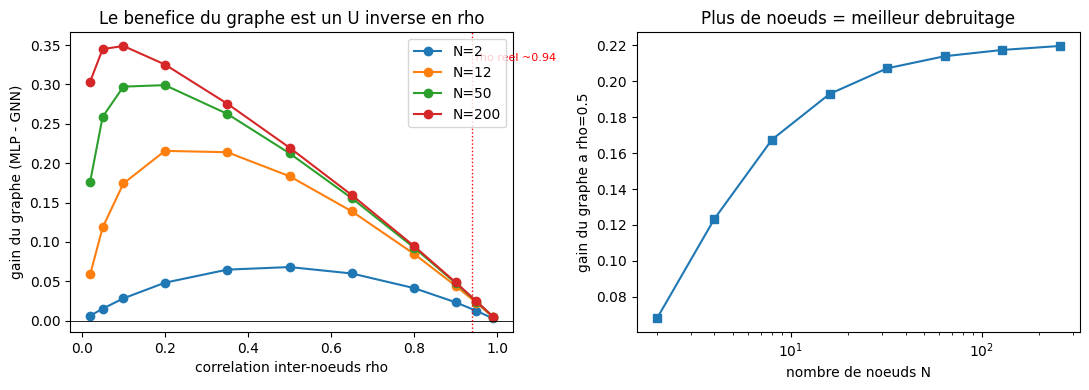

N=12 : pic du benefice a rho = 0.20, gain 0.216
a rho=0.95 (proche du reel) le gain tombe a 0.022


In [31]:
def _gen(n_nodes, n_samples, rho, kappa, seed):
    """y_i = d + kappa*u_i ; x_i = d + xi_i, with rho = var(d)/(var(d)+var(xi))."""
    rng = np.random.default_rng(seed)
    s2 = (1.0 - rho) / max(rho, 1e-9)
    d = rng.standard_normal((n_samples, 1))
    u = rng.standard_normal((n_samples, n_nodes))
    xi = rng.standard_normal((n_samples, n_nodes)) * np.sqrt(s2)
    return d + xi, d + kappa * u          # X, Y

def _ridge(Xtr, ytr, Xte, lam=1e-1):
    w = np.linalg.solve(Xtr.T @ Xtr + lam * np.eye(Xtr.shape[1]), Xtr.T @ ytr)
    return Xte @ w

def _eval(n_nodes, rho, kappa, seed, ntr=2000, nte=2000):
    """Per-node model (own feature) vs graph model (own feature + neighbour mean)."""
    Xtr, Ytr = _gen(n_nodes, ntr, rho, kappa, seed)
    Xte, Yte = _gen(n_nodes, nte, rho, kappa, seed + 10_000)
    em, eg = [], []
    for i in range(n_nodes):
        own_tr, own_te = Xtr[:, [i]], Xte[:, [i]]
        nb_tr = (Xtr.sum(1, keepdims=True) - Xtr[:, [i]]) / max(n_nodes - 1, 1)
        nb_te = (Xte.sum(1, keepdims=True) - Xte[:, [i]]) / max(n_nodes - 1, 1)
        yt, ye = Ytr[:, [i]], Yte[:, [i]]
        em.append(rmse(_ridge(own_tr, yt, own_te), ye))
        eg.append(rmse(_ridge(np.hstack([own_tr, nb_tr]), yt, np.hstack([own_te, nb_te])), ye))
    return float(np.mean(em)), float(np.mean(eg))

SEEDS_F = list(range(8))
RHOS = [0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9, 0.95, 0.99]
def curve(n):
    return [(r, np.mean([_eval(n, r, 1.0, s)[0] - _eval(n, r, 1.0, s)[1] for s in SEEDS_F])) for r in RHOS]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n in [2, 12, 50, 200]:
    c = curve(n); ax[0].plot([x[0] for x in c], [x[1] for x in c], "o-", label=f"N={n}")
ax[0].axhline(0, color="k", lw=0.6); ax[0].axvline(0.94, color="r", ls=":", lw=1)
ax[0].text(0.94, ax[0].get_ylim()[1]*0.9, " rho reel ~0.94", color="r", fontsize=8)
ax[0].set_xlabel("correlation inter-noeuds rho"); ax[0].set_ylabel("gain du graphe (MLP - GNN)")
ax[0].set_title("Le benefice du graphe est un U inverse en rho"); ax[0].legend()
NS = [2, 4, 8, 16, 32, 64, 128, 256]
gg = [np.mean([_eval(n, 0.5, 1.0, s)[0] - _eval(n, 0.5, 1.0, s)[1] for s in SEEDS_F]) for n in NS]
ax[1].plot(NS, gg, "s-"); ax[1].set_xscale("log")
ax[1].set_xlabel("nombre de noeuds N"); ax[1].set_ylabel("gain du graphe a rho=0.5")
ax[1].set_title("Plus de noeuds = meilleur debruitage")
plt.tight_layout(); plt.show()

peak = max(curve(12), key=lambda r: r[1])
print(f"N=12 : pic du benefice a rho = {peak[0]:.2f}, gain {peak[1]:.3f}")
print(f"a rho=0.95 (proche du reel) le gain tombe a "
      f"{np.mean([_eval(12,0.95,1.0,s)[0]-_eval(12,0.95,1.0,s)[1] for s in SEEDS_F]):.3f}")

### Faut-il ajouter des nœuds factices ?

Le débruitage s'améliore avec le nombre d'observations indépendantes du pilote, ce que la courbe de
droite montre en fonction de $N$. On peut donc se demander si des nœuds ajoutés aideraient. La
réponse tient à ce que ces nœuds observent. Ajouter des nœuds qui regardent le même pilote, avec un
bruit indépendant, apporte des vues supplémentaires et améliore l'estimation. Ajouter des nœuds qui
portent leur propre pilote, sans lien avec celui des nœuds réels, ne fait que polluer la moyenne de
voisinage, et non seulement ces nœuds n'aident pas, ils détruisent le bénéfice que les vrais voisins
procuraient. Un nœud factice ne vaut donc rien s'il ne porte pas une observation réelle du signal
partagé.

In [ ]:
def _eval_aug(n_real, n_added, kind, rho, kappa, seed, ntr=2000, nte=2000):
    rng = np.random.default_rng(seed); s2 = (1.0 - rho) / max(rho, 1e-9); S = ntr + nte
    d = rng.standard_normal((S, 1))
    Xr = d + rng.standard_normal((S, n_real)) * np.sqrt(s2)
    Yr = d + kappa * rng.standard_normal((S, n_real))
    if n_added:
        da = d if kind == "shared" else rng.standard_normal((S, 1))
        Xa = da + rng.standard_normal((S, n_added)) * np.sqrt(s2)
    else:
        Xa = np.zeros((S, 0))
    Xall = np.hstack([Xr, Xa]); em, eg = [], []
    for i in range(n_real):
        own = Xr[:, [i]]; nb = (Xall.sum(1, keepdims=True) - Xr[:, [i]]) / (Xall.shape[1] - 1)
        yi = Yr[:, [i]]
        em.append(rmse(_ridge(own[:ntr], yi[:ntr], own[ntr:]), yi[ntr:]))
        eg.append(rmse(_ridge(np.hstack([own, nb])[:ntr], yi[:ntr], np.hstack([own, nb])[ntr:]), yi[ntr:]))
    return float(np.mean(em)), float(np.mean(eg))

print("12 noeuds reels (rho=0.4) + K noeuds ajoutes, gain du graphe sur les noeuds reels\n")
rows = []
for kind in ("shared", "independent"):
    for K in [0, 12, 48, 188]:
        gains = [(lambda em, eg: em - eg)(*_eval_aug(12, K, kind, 0.4, 1.0, s)) for s in SEEDS_F]
        rows.append({"noeuds ajoutes": K, "type": kind, "gain reel": round(float(np.mean(gains)), 4)})
display(pd.DataFrame(rows).pivot(index="noeuds ajoutes", columns="type", values="gain reel"))

## Ce que ces mesures établissent, et ce qu'elles ne peuvent pas établir

Le tableau de la partie A et la courbe de la partie C répondent à deux questions distinctes, et
c'est leur écart qui est instructif. Une part des voisins élevée dit que l'opérateur lit le graphe,
elle ne dit pas que cette lecture serve. Une part faible, en revanche, suffit à disqualifier toute
interprétation du graphe pour l'opérateur concerné, puisqu'il n'y a rien à interpréter dans une
contribution que le modèle n'utilise pas.

Trois limites bornent ce qui précède. Le nombre de graines reste petit, de sorte que tout écart
inférieur à la dispersion reportée doit être tenu pour du bruit, et cela vaut d'abord pour les
classements d'opérateurs, qui se sont déjà révélés ailleurs entièrement contenus dans le bruit de
graine. La largeur des couches est choisie sur validation pour les perceptrons mais fixée pour les
réseaux sur graphe, ce qui avantage légèrement les premiers, et une recherche d'hyperparamètres
symétrique serait nécessaire avant de conclure sur un écart de quelques dizaines de mégawatts. Le
protocole enfin ne fait varier que la taille de l'échantillon, à nombre de nœuds constant.

Cette dernière limite est la plus lourde, parce que le partage de poids est l'hypothèse qui reste
debout. Douze nœuds riches en données donnent à douze modèles indépendants de quoi s'estimer
séparément, et le partage leur coûte alors plus qu'il ne leur rapporte. L'axe qui manque est celui
du nombre de nœuds, là où chaque nœud devient pauvre et où le partage cesse d'être un luxe pour
devenir la seule estimation possible. Les cinq cents postes du jeu WEAVE-UK offrent ce régime, et
c'est là que le biais devrait se montrer s'il existe.